In [1]:
# ============================================================
# NOTEBOOK 13
# Final Visualization & Paper Results
# ============================================================

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

print("="*80)
print("Notebook 13")
print("Final Visualization & Paper Results")
print("="*80)

Notebook 13
Final Visualization & Paper Results


In [2]:
# ============================================================
# Cell 2
# Project Paths
# ============================================================

PROJECT_ROOT = Path(
    r"D:\Research\Papers\Paper_2"
)

RESULT_DIR = PROJECT_ROOT / "results"

MERGED_DIR = RESULT_DIR / "merged"

FIGURE_DIR = PROJECT_ROOT / "figures" / "paper"

MODEL_DIR = PROJECT_ROOT / "models"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project :", PROJECT_ROOT)
print("Merged  :", MERGED_DIR)
print("Figures :", FIGURE_DIR)
print("Models  :", MODEL_DIR)

Project : D:\Research\Papers\Paper_2
Merged  : D:\Research\Papers\Paper_2\results\merged
Figures : D:\Research\Papers\Paper_2\figures\paper
Models  : D:\Research\Papers\Paper_2\models


In [3]:
# ============================================================
# Cell 3
# Load Final Datasets
# ============================================================

ml_dataset = pd.read_csv(
    MERGED_DIR /
    "merged_localization_ml_dataset.csv"
)

trajectory = pd.read_csv(
    MERGED_DIR /
    "merged_fusion_trajectory.csv"
)

weights = pd.read_csv(
    MERGED_DIR /
    "merged_adaptive_sensor_weights.csv"
)

confidence = pd.read_csv(
    MERGED_DIR /
    "merged_sensor_confidence_index.csv"
)

print("="*80)
print("Datasets Loaded Successfully")
print("="*80)

print()

print("ML Dataset")
print(ml_dataset.shape)

print()

print("Trajectory")
print(trajectory.shape)

print()

print("Weights")
print(weights.shape)

print()

print("Confidence")
print(confidence.shape)

print()

print("="*80)

Datasets Loaded Successfully

ML Dataset
(2472, 76)

Trajectory
(2472, 15)

Weights
(2472, 15)

Confidence
(2472, 44)



In [4]:
# ============================================================
# Cell 4
# Dataset Overview
# ============================================================

summary = pd.DataFrame({

    "Property":[

        "Total Samples",

        "Total Features",

        "Number of Drives",

        "Average Adaptive Error",

        "Average Baseline Error"

    ],

    "Value":[

        len(trajectory),

        ml_dataset.shape[1],

        trajectory["Drive"].nunique(),

        trajectory["Adaptive Position Error (m)"].mean(),

        trajectory["Baseline Position Error (m)"].mean()

    ]

})

display(summary)

print()

print("="*80)
print("Dataset Summary")
print("="*80)

print(summary)

,Property,Value
0,Total Samples,2472.000000
1,Total Features,76.000000
2,Number of Drives,9.000000
3,Average Adaptive Error,0.116408
4,Average Baseline Error,0.114193



Dataset Summary
                 Property        Value
0           Total Samples  2472.000000
1          Total Features    76.000000
2        Number of Drives     9.000000
3  Average Adaptive Error     0.116408
4  Average Baseline Error     0.114193


In [5]:
# ============================================================
# Cell 5
# Overall Performance Summary
# ============================================================

adaptive_rmse = np.sqrt(

    np.mean(

        trajectory["Adaptive Position Error (m)"]**2

    )

)

baseline_rmse = np.sqrt(

    np.mean(

        trajectory["Baseline Position Error (m)"]**2

    )

)

adaptive_mae = trajectory[
    "Adaptive Position Error (m)"
].mean()

baseline_mae = trajectory[
    "Baseline Position Error (m)"
].mean()

performance = pd.DataFrame({

    "Method":[

        "Baseline Localization",

        "Adaptive Localization"

    ],

    "RMSE (m)":[

        baseline_rmse,

        adaptive_rmse

    ],

    "MAE (m)":[

        baseline_mae,

        adaptive_mae

    ]

})

display(performance)

print()

print("="*80)
print("Localization Performance Summary")
print("="*80)

print(performance)

,Method,RMSE (m),MAE (m)
0,Baseline Localization,0.139337,0.114193
1,Adaptive Localization,0.142856,0.116408



Localization Performance Summary
                  Method  RMSE (m)   MAE (m)
0  Baseline Localization  0.139337  0.114193
1  Adaptive Localization  0.142856  0.116408


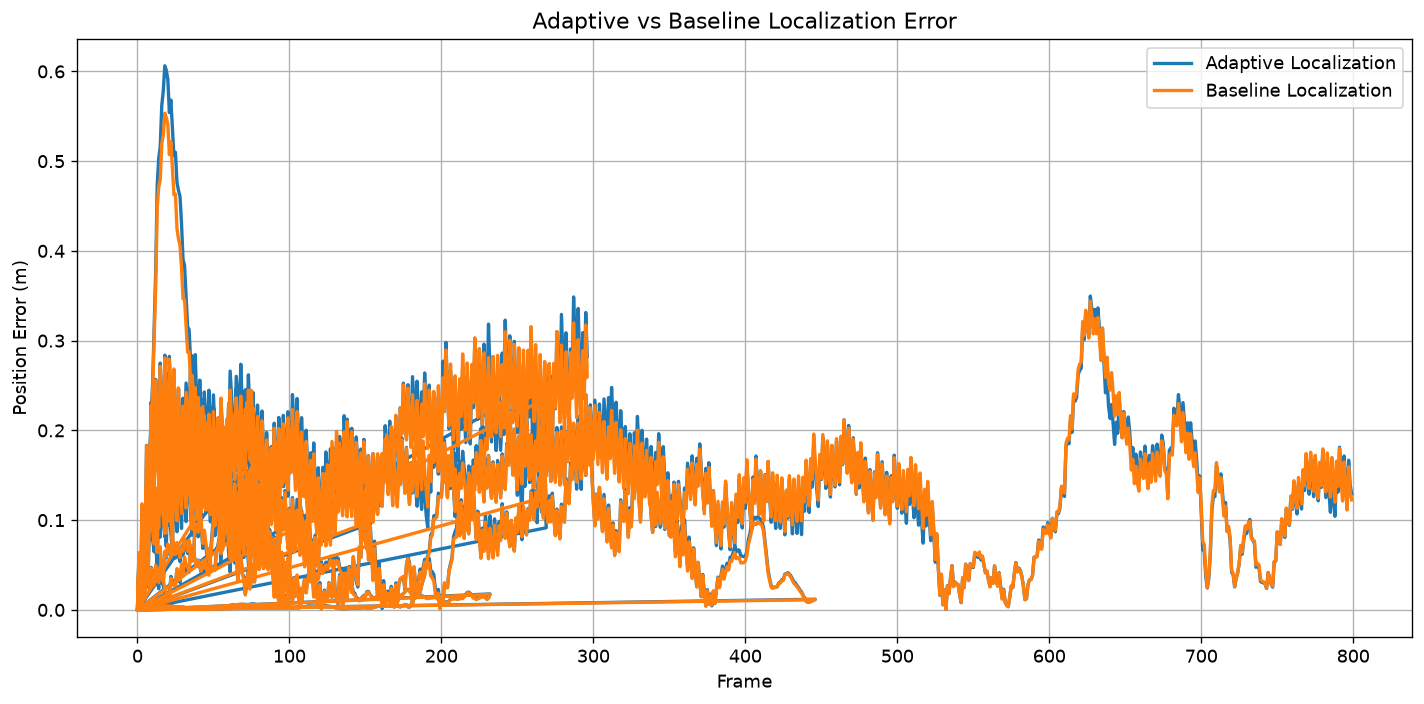

In [6]:
# ============================================================
# Cell 6
# Figure 1
# Adaptive vs Baseline Localization Error
# ============================================================

plt.figure(figsize=(12,6))

plt.plot(
    trajectory["Frame"],
    trajectory["Adaptive Position Error (m)"],
    linewidth=2,
    label="Adaptive Localization"
)

plt.plot(
    trajectory["Frame"],
    trajectory["Baseline Position Error (m)"],
    linewidth=2,
    label="Baseline Localization"
)

plt.xlabel("Frame")
plt.ylabel("Position Error (m)")
plt.title("Adaptive vs Baseline Localization Error")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig01_adaptive_vs_baseline_error.png",
    dpi=300
)

plt.show()

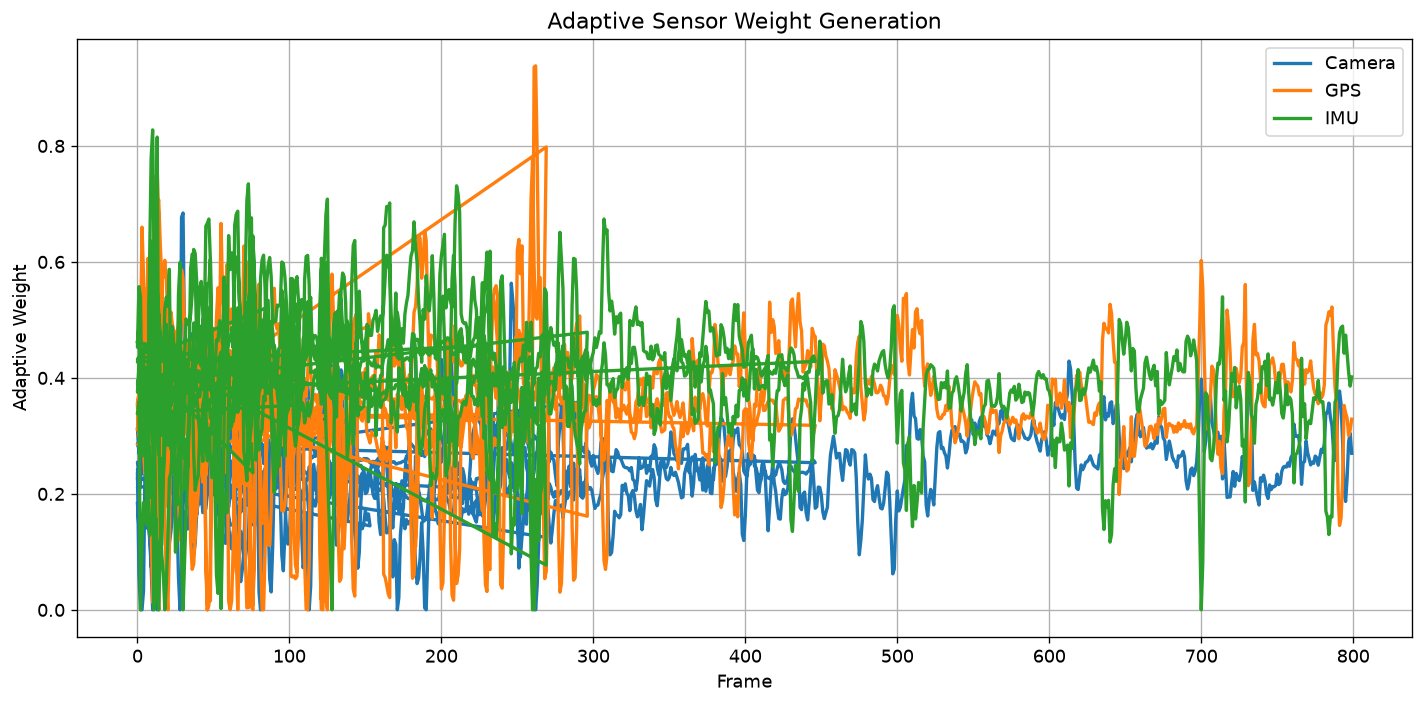

In [7]:
# ============================================================
# Cell 7
# Figure 2
# Adaptive Sensor Weights
# ============================================================

plt.figure(figsize=(12,6))

plt.plot(
    weights["Frame"],
    weights["Camera Weight"],
    linewidth=2,
    label="Camera"
)

plt.plot(
    weights["Frame"],
    weights["GPS Weight"],
    linewidth=2,
    label="GPS"
)

plt.plot(
    weights["Frame"],
    weights["IMU Weight"],
    linewidth=2,
    label="IMU"
)

plt.xlabel("Frame")
plt.ylabel("Adaptive Weight")
plt.title("Adaptive Sensor Weight Generation")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig02_sensor_weights.png",
    dpi=300
)

plt.show()

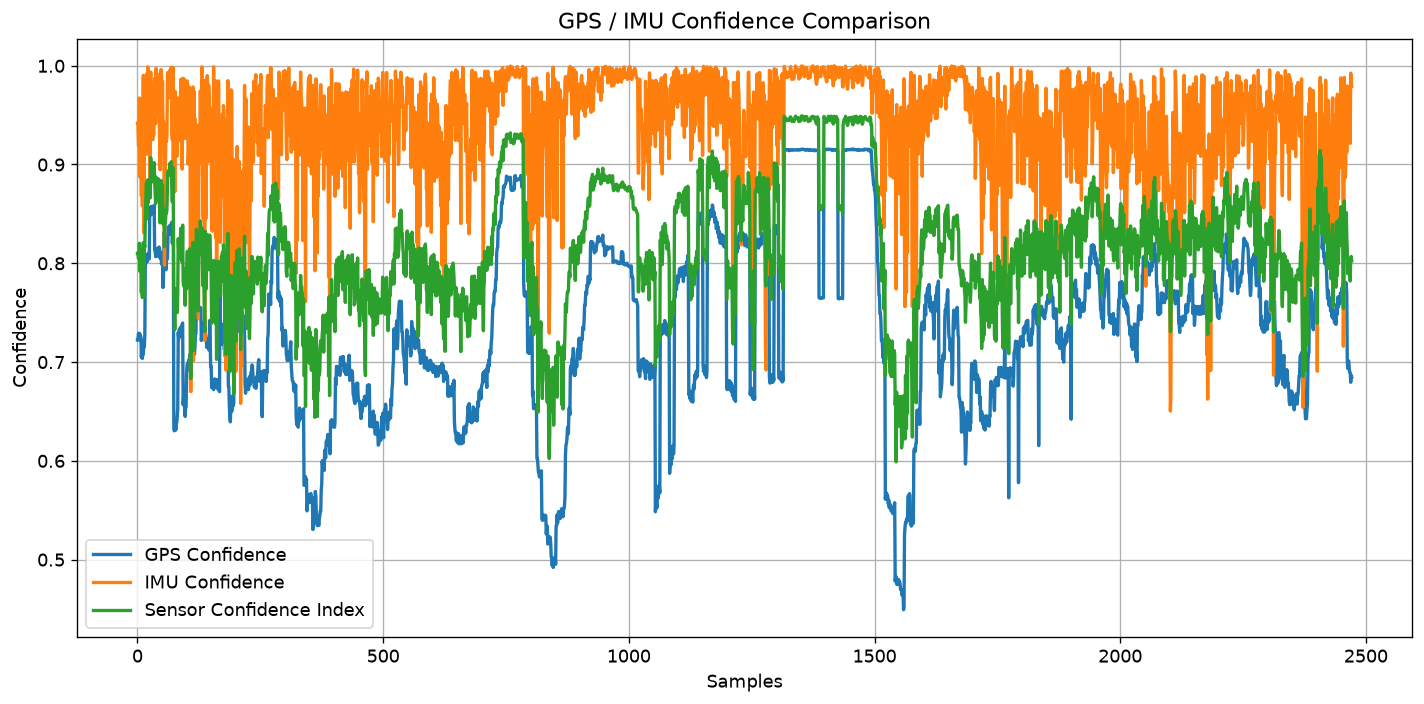

In [8]:
# ============================================================
# Cell 8
# GPS & IMU Confidence
# ============================================================

x = np.arange(len(confidence))

plt.figure(figsize=(12,6))

plt.plot(
    x,
    confidence["GPS Confidence"],
    linewidth=2,
    label="GPS Confidence"
)

plt.plot(
    x,
    confidence["IMU Confidence"],
    linewidth=2,
    label="IMU Confidence"
)

plt.plot(
    x,
    confidence["Sensor Confidence Index"],
    linewidth=2,
    label="Sensor Confidence Index"
)

plt.xlabel("Samples")
plt.ylabel("Confidence")
plt.title("GPS / IMU Confidence Comparison")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig03_sensor_confidence.png",
    dpi=300
)

plt.show()

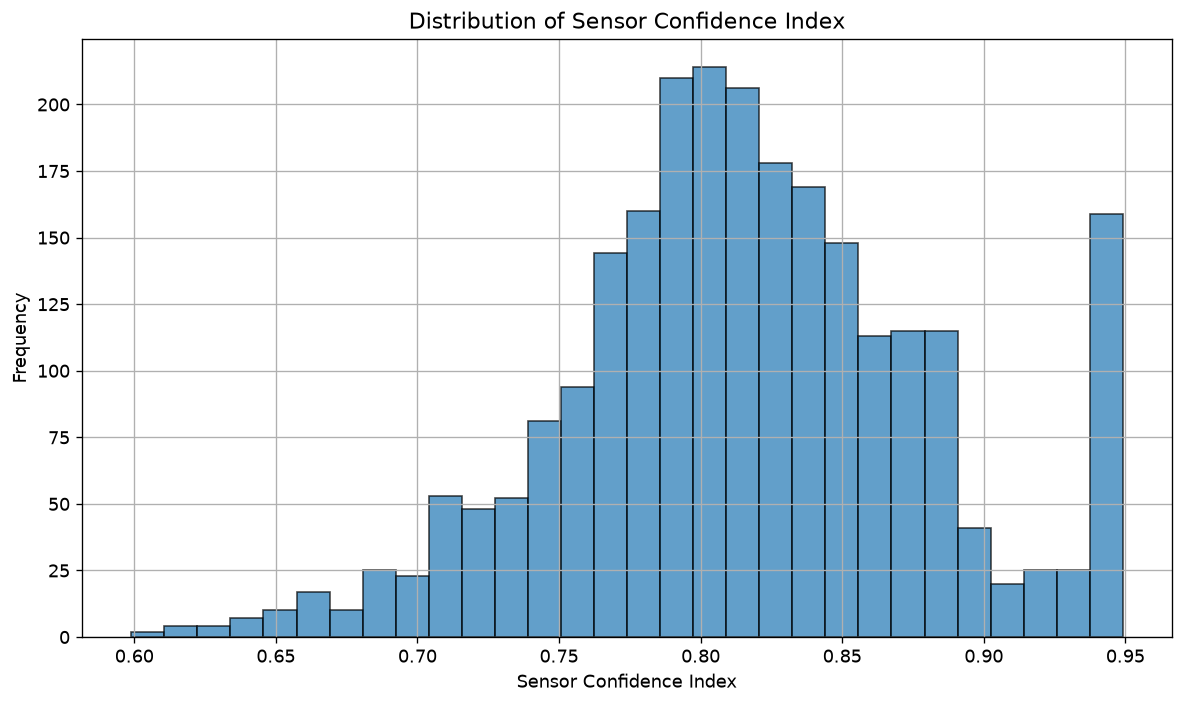

In [9]:
# ============================================================
# Cell 9
# Figure 4
# Confidence Distribution
# ============================================================

plt.figure(figsize=(10,6))

plt.hist(
    confidence["Sensor Confidence Index"],
    bins=30,
    alpha=0.7,
    edgecolor="black"
)

plt.xlabel("Sensor Confidence Index")
plt.ylabel("Frequency")
plt.title("Distribution of Sensor Confidence Index")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig04_confidence_distribution.png",
    dpi=300
)

plt.show()

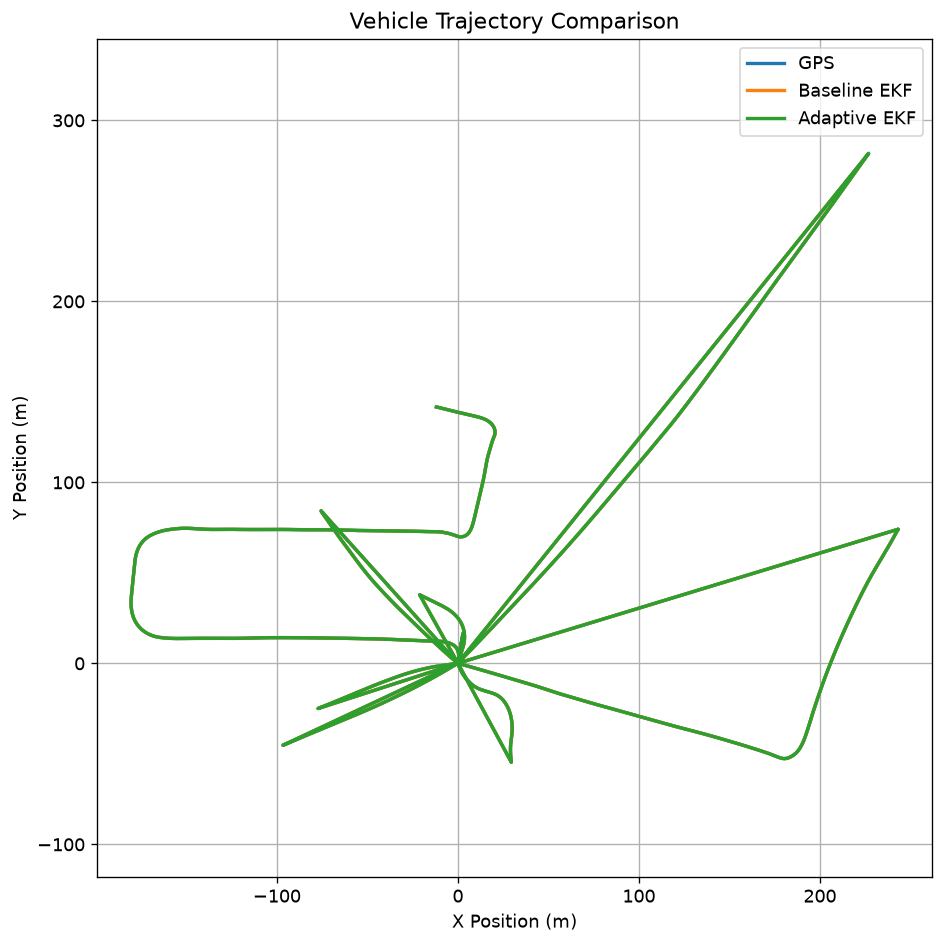

In [10]:
# ============================================================
# Cell 10
# Figure 5
# Trajectory Comparison
# ============================================================

plt.figure(figsize=(8,8))

plt.plot(
    trajectory["X GPS"],
    trajectory["Y GPS"],
    linewidth=2,
    label="GPS"
)

plt.plot(
    trajectory["X Baseline"],
    trajectory["Y Baseline"],
    linewidth=2,
    label="Baseline EKF"
)

plt.plot(
    trajectory["X Adaptive"],
    trajectory["Y Adaptive"],
    linewidth=2,
    label="Adaptive EKF"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Vehicle Trajectory Comparison")

plt.axis("equal")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig05_trajectory_comparison.png",
    dpi=300
)

plt.show()

In [11]:
# ============================================================
# Cell 11
# Load Machine Learning Results
# ============================================================

comparison = pd.read_csv(
    RESULT_DIR /
    "model_comparison.csv"
)

importance = pd.read_csv(
    RESULT_DIR /
    "feature_importance.csv"
)

prediction = pd.read_csv(
    RESULT_DIR /
    "localization_error_prediction.csv"
)

print("="*80)
print("Machine Learning Results Loaded")
print("="*80)

display(comparison)
display(importance.head())
display(prediction.head())

Machine Learning Results Loaded


,Model,RMSE,MAE,R2
0,Random Forest,0.020713,0.015463,0.941140
1,Gradient Boosting,0.025532,0.018837,0.910561
2,Linear Regression,0.028374,0.020637,0.889546


,Feature,Importance
0,Covariance Trace,0.392177
1,Innovation Norm,0.300820
2,Velocity,0.272073
3,Yaw Rate,0.014308
4,Localization Reliability Score,0.007374


,Actual Position Error,Predicted Position Error
0,1.116223,1.087691
1,0.575213,0.625318
2,0.664226,0.712857
3,1.397210,1.382980
4,1.144283,1.142593


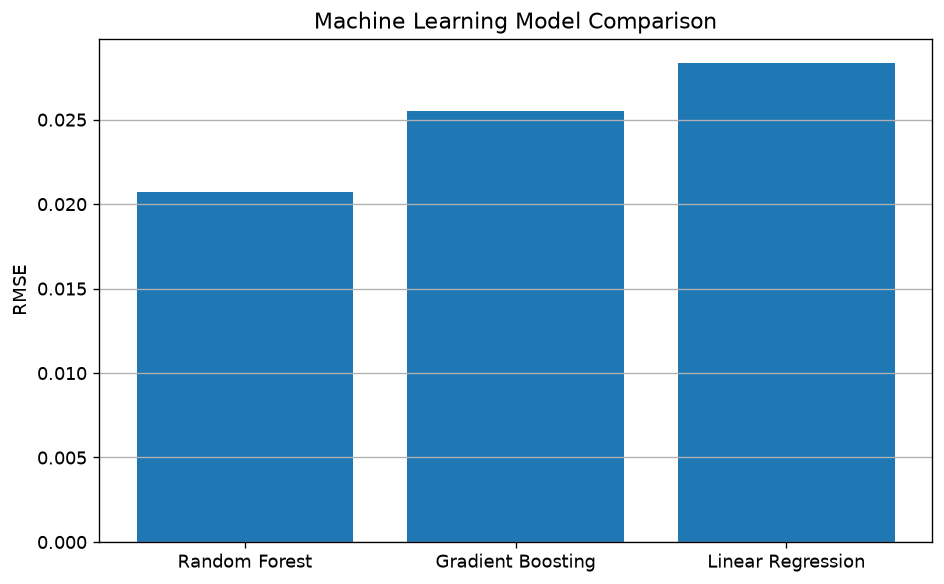

,Model,RMSE,MAE,R2
0,Random Forest,0.020713,0.015463,0.941140
1,Gradient Boosting,0.025532,0.018837,0.910561
2,Linear Regression,0.028374,0.020637,0.889546


In [12]:
# ============================================================
# Cell 12
# Figure 6
# Model Comparison
# ============================================================

fig, ax = plt.subplots(figsize=(8,5))

ax.bar(
    comparison["Model"],
    comparison["RMSE"]
)

ax.set_title("Machine Learning Model Comparison")
ax.set_ylabel("RMSE")
ax.grid(True, axis="y")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig06_model_comparison.png",
    dpi=300
)

plt.show()

display(comparison)

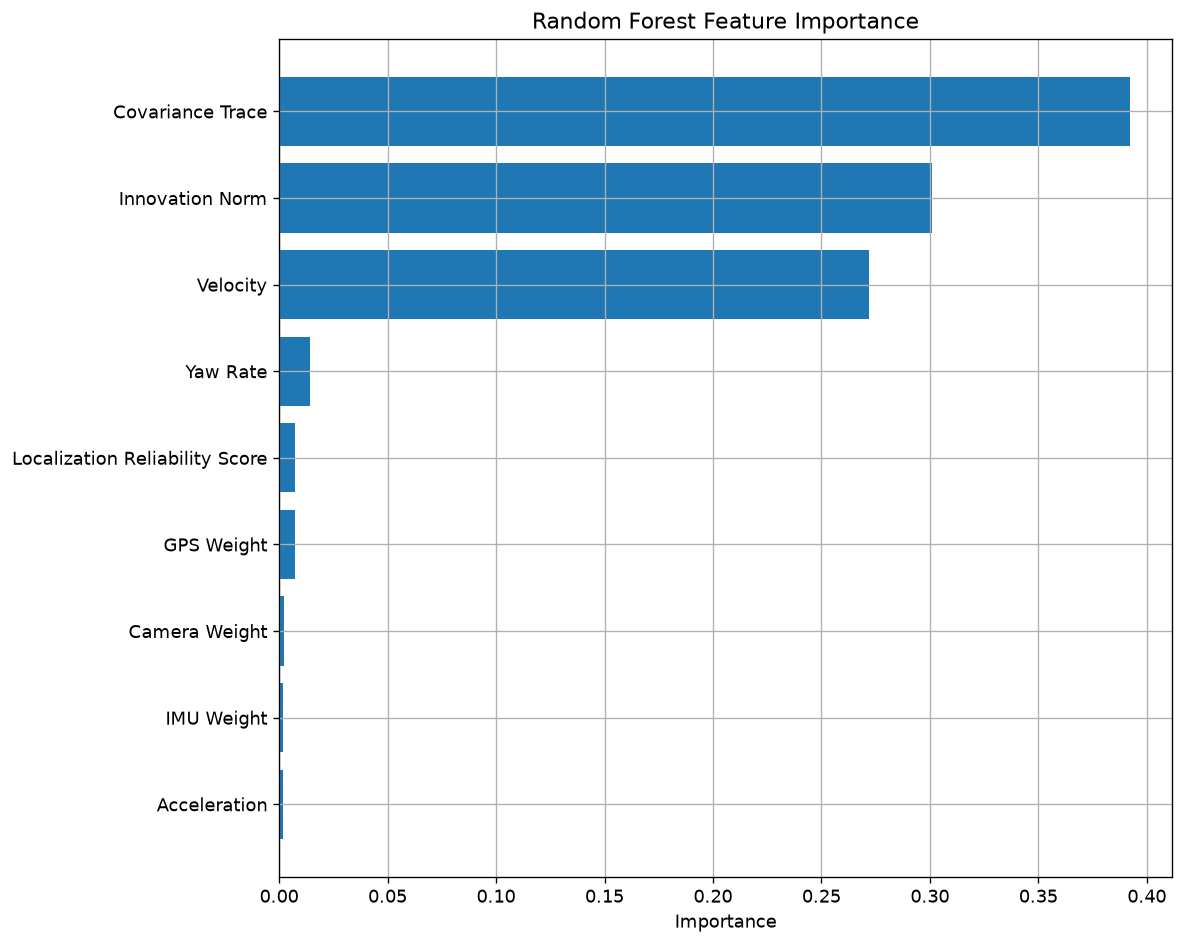

,Feature,Importance
8,Acceleration,0.001689
7,IMU Weight,0.001941
6,Camera Weight,0.002361
5,GPS Weight,0.007255
4,Localization Reliability Score,0.007374
3,Yaw Rate,0.014308
2,Velocity,0.272073
1,Innovation Norm,0.300820
0,Covariance Trace,0.392177


In [13]:
# ============================================================
# Cell 13
# Figure 7
# Feature Importance
# ============================================================

importance = importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10,8))

plt.barh(

    importance["Feature"],

    importance["Importance"]

)

plt.xlabel("Importance")

plt.title(
    "Random Forest Feature Importance"
)

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "fig07_feature_importance.png",
    dpi=300
)

plt.show()

display(
    importance.tail(15)
)

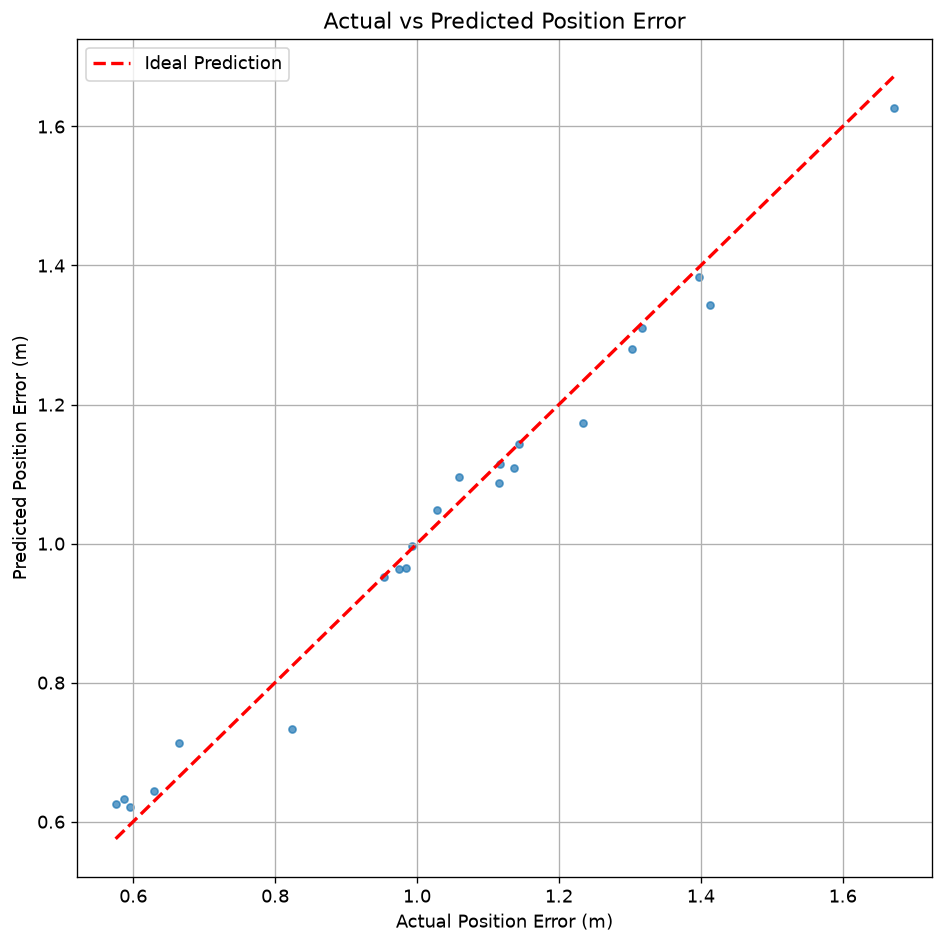

In [14]:
# ============================================================
# Cell 14
# Figure 8
# Actual vs Predicted Position Error
# ============================================================

plt.figure(figsize=(8,8))

plt.scatter(

    prediction["Actual Position Error"],

    prediction["Predicted Position Error"],

    s=18,

    alpha=0.7

)

minimum = min(

    prediction["Actual Position Error"].min(),

    prediction["Predicted Position Error"].min()

)

maximum = max(

    prediction["Actual Position Error"].max(),

    prediction["Predicted Position Error"].max()

)

plt.plot(

    [minimum, maximum],

    [minimum, maximum],

    "r--",

    linewidth=2,

    label="Ideal Prediction"

)

plt.xlabel("Actual Position Error (m)")

plt.ylabel("Predicted Position Error (m)")

plt.title("Actual vs Predicted Position Error")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "fig08_actual_vs_predicted.png",

    dpi=300

)

plt.show()

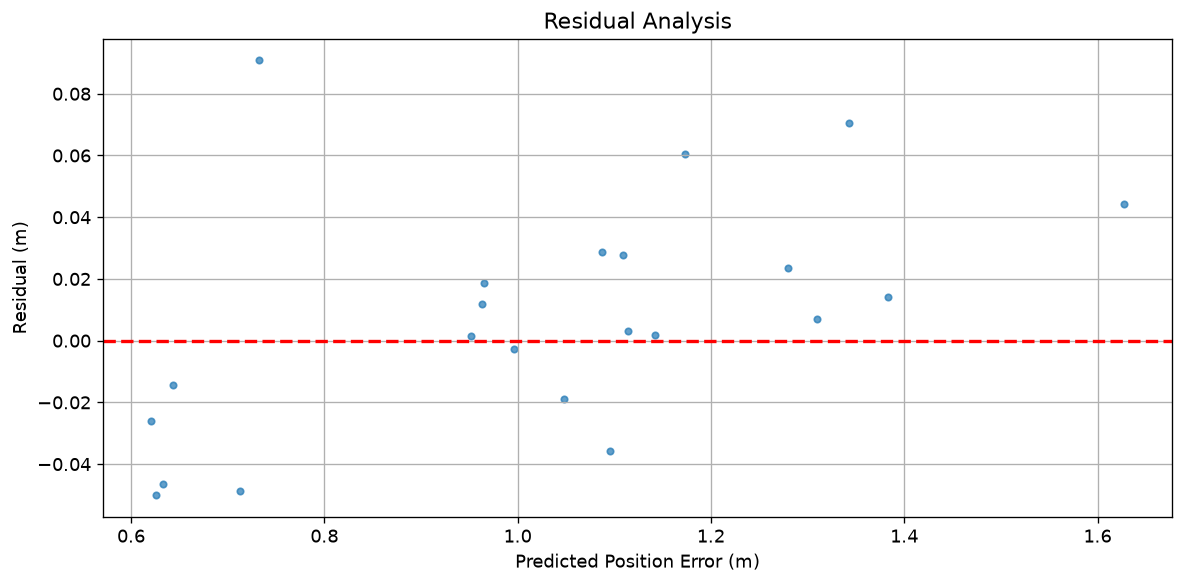

Machine Learning Figures Generated Successfully


In [15]:
# ============================================================
# Cell 15
# Figure 9
# Residual Analysis
# ============================================================

prediction["Residual"] = (

    prediction["Actual Position Error"]

    -

    prediction["Predicted Position Error"]

)

plt.figure(figsize=(10,5))

plt.scatter(

    prediction["Predicted Position Error"],

    prediction["Residual"],

    s=15,

    alpha=0.7

)

plt.axhline(

    0,

    color="red",

    linestyle="--",

    linewidth=2

)

plt.xlabel("Predicted Position Error (m)")

plt.ylabel("Residual (m)")

plt.title("Residual Analysis")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "fig09_residual_analysis.png",

    dpi=300

)

plt.show()

print("="*80)

print("Machine Learning Figures Generated Successfully")

print("="*80)

,Drive,Adaptive_RMSE,Baseline_RMSE
0,2011_09_26_drive_0001_sync,0.094600,0.102664
1,2011_09_26_drive_0002_sync,0.155865,0.156056
2,2011_09_26_drive_0005_sync,0.061051,0.061733
3,2011_09_26_drive_0009_sync,0.148907,0.141146
4,2011_09_26_drive_0011_sync,0.103678,0.100246
5,2011_09_26_drive_0015_sync,0.194202,0.190239
6,2011_09_26_drive_0018_sync,0.080146,0.081933
7,2011_09_26_drive_0020_sync,0.088157,0.085059
8,2011_09_26_drive_0022_sync,0.162086,0.157968


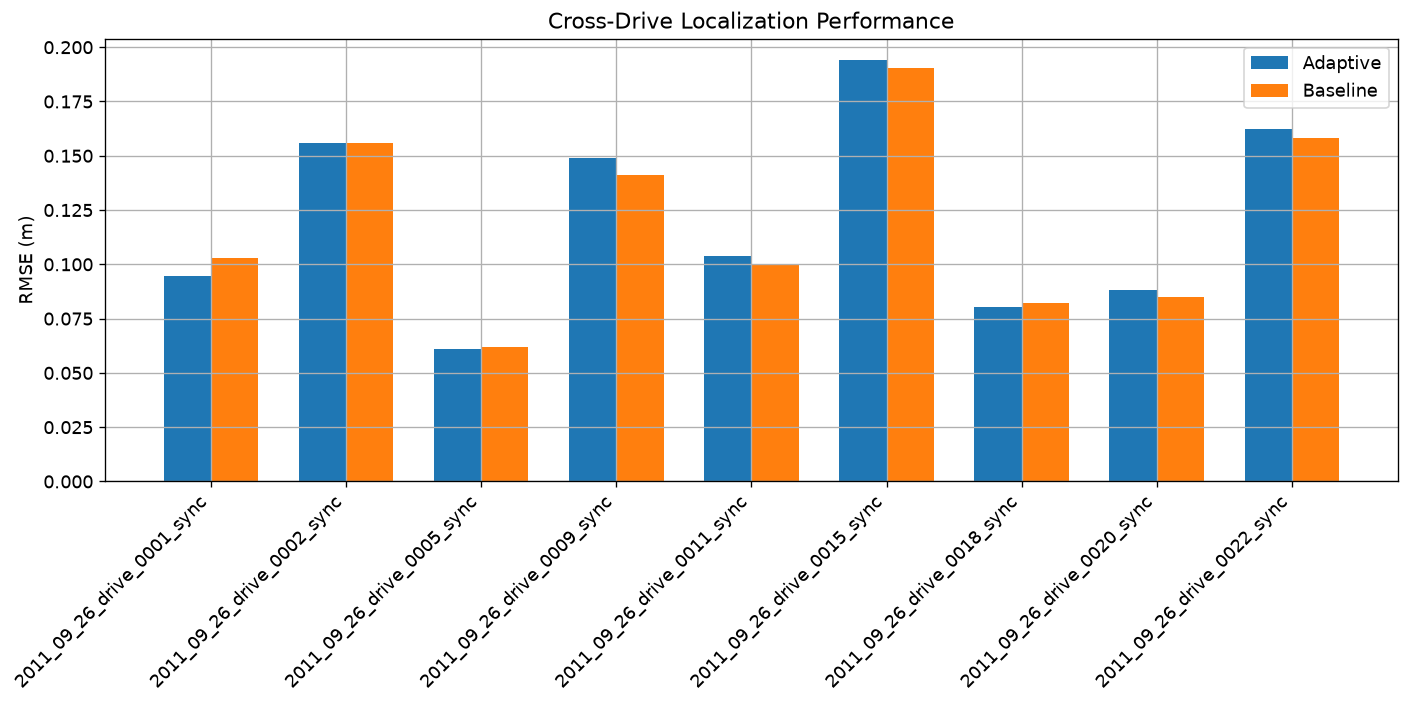

In [16]:
# ============================================================
# Cell 16
# Figure 10
# Cross Drive Performance
# ============================================================

drive_summary = (

    trajectory

    .groupby("Drive")

    .agg(

        Adaptive_RMSE=("Adaptive Position Error (m)",

                       lambda x: np.sqrt(np.mean(x**2))),

        Baseline_RMSE=("Baseline Position Error (m)",

                       lambda x: np.sqrt(np.mean(x**2)))

    )

    .reset_index()

)

display(drive_summary)

plt.figure(figsize=(12,6))

x = np.arange(len(drive_summary))

width = 0.35

plt.bar(

    x - width/2,

    drive_summary["Adaptive_RMSE"],

    width,

    label="Adaptive"

)

plt.bar(

    x + width/2,

    drive_summary["Baseline_RMSE"],

    width,

    label="Baseline"

)

plt.xticks(

    x,

    drive_summary["Drive"],

    rotation=45,

    ha="right"

)

plt.ylabel("RMSE (m)")

plt.title("Cross-Drive Localization Performance")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "fig10_cross_drive_performance.png",

    dpi=300

)

plt.show()

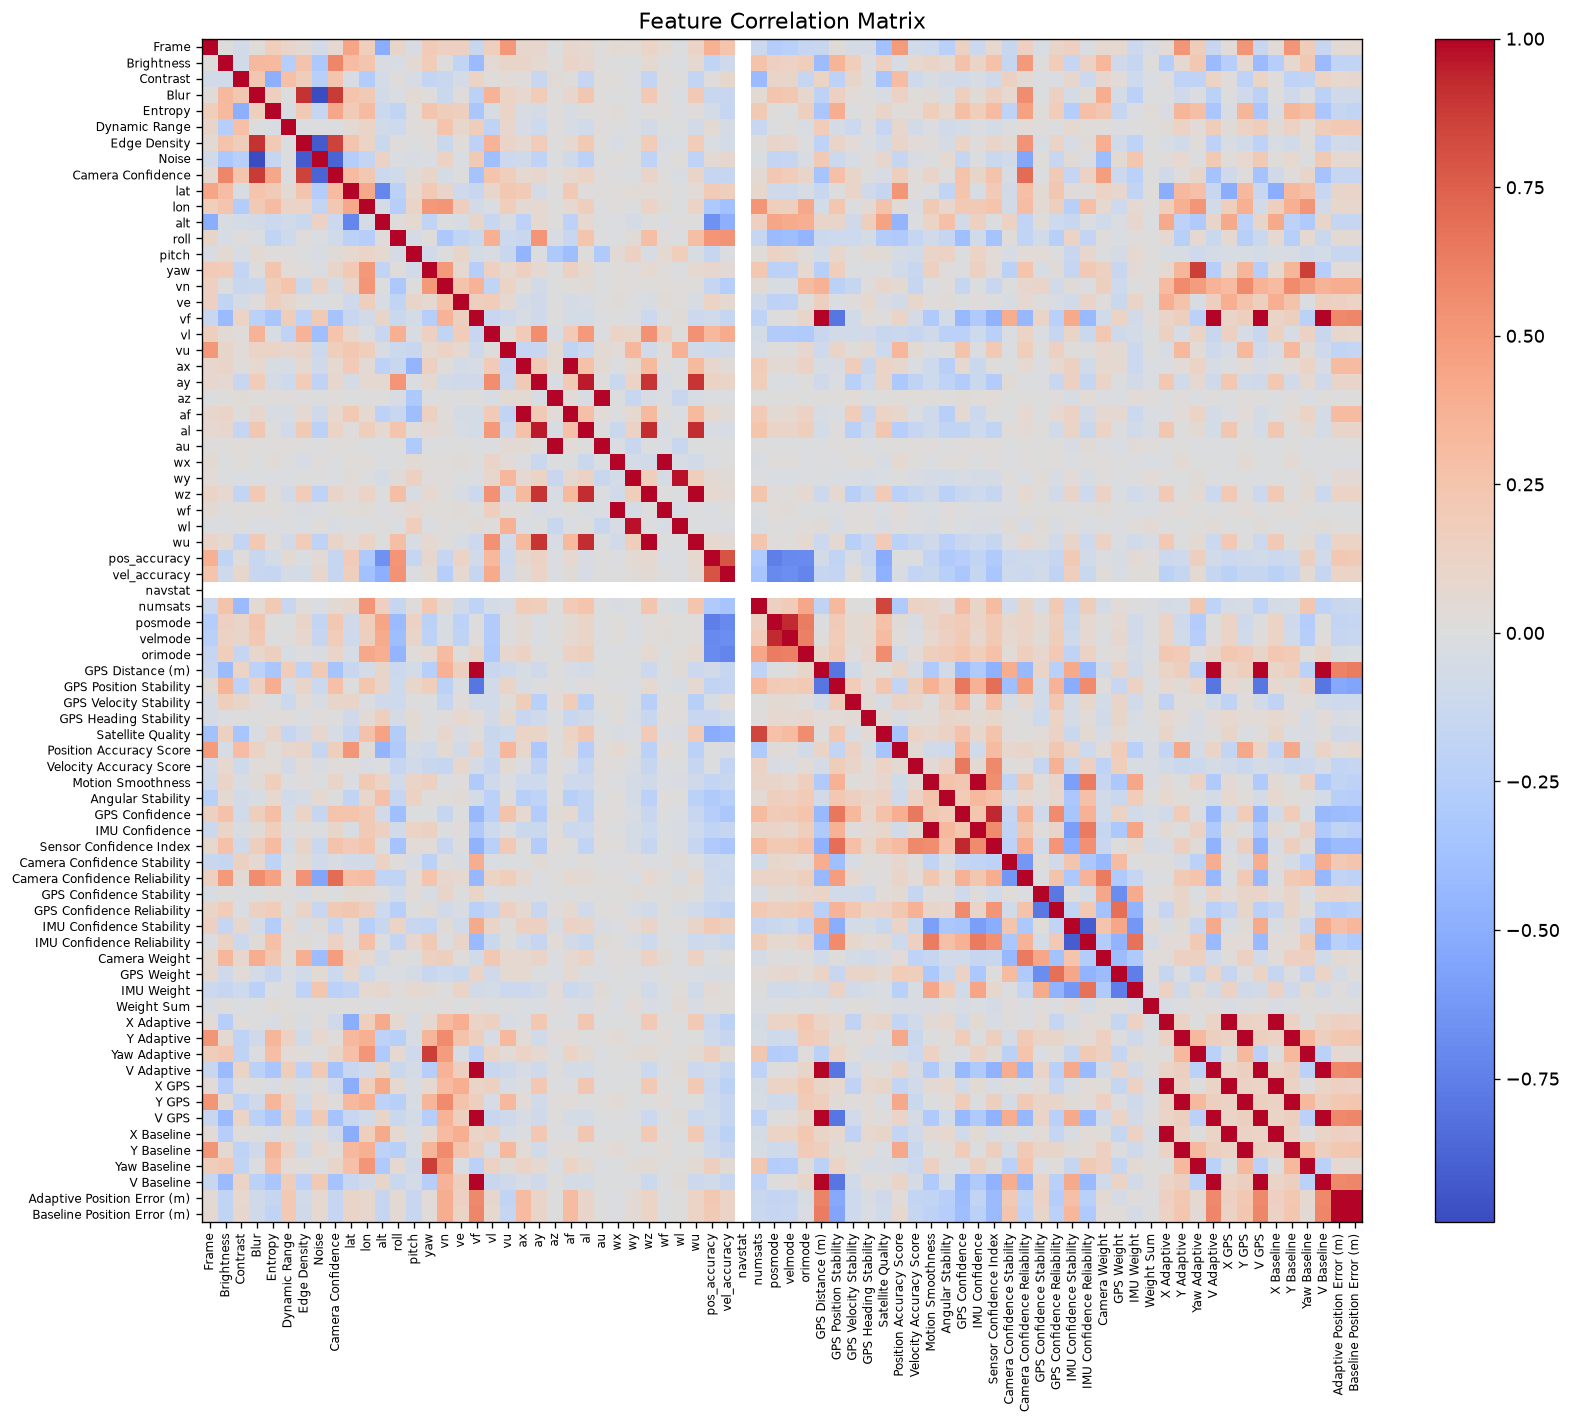

In [17]:
# ============================================================
# Cell 17
# Figure 11
# Correlation Heatmap
# ============================================================

numeric_df = ml_dataset.select_dtypes(

    include=np.number

)

correlation = numeric_df.corr()

plt.figure(figsize=(14,12))

plt.imshow(

    correlation,

    cmap="coolwarm",

    interpolation="nearest",

    aspect="auto"

)

plt.xticks(

    range(len(correlation.columns)),

    correlation.columns,

    rotation=90,

    fontsize=7

)

plt.yticks(

    range(len(correlation.columns)),

    correlation.columns,

    fontsize=7

)

plt.colorbar()

plt.title(

    "Feature Correlation Matrix"

)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "fig11_correlation_heatmap.png",

    dpi=300

)

plt.show()

In [18]:
# ============================================================
# Cell 18
# Final Research Summary
# ============================================================

print("="*90)

print("NOTEBOOK 13 COMPLETED SUCCESSFULLY")

print("="*90)

print()

print("Project")

print("----------------------------")

print("Confidence-Driven Adaptive Multi-Sensor Fusion Framework")

print()

print("Dataset")

print("----------------------------")

print(f"Total Drives : {trajectory['Drive'].nunique()}")

print(f"Total Frames : {len(trajectory)}")

print(f"Total Features : {ml_dataset.shape[1]}")

print()

print("Localization Performance")

print("----------------------------")

print(f"Adaptive RMSE : {adaptive_rmse:.4f} m")

print(f"Baseline RMSE : {baseline_rmse:.4f} m")

print()

print("Machine Learning")

print("----------------------------")

print("Best Model : Random Forest")

print()

print("Generated Paper Figures")

print("----------------------------")

for file in sorted(FIGURE_DIR.glob("*.png")):

    print(file.name)

print()

print("="*90)

print("RESEARCH PIPELINE COMPLETED")

print("="*90)

print()

print("Ready for:")

print("✓ SCI Journal Paper")

print("✓ Thesis")

print("✓ Conference Presentation")

print("✓ Final Dissertation")

print("="*90)

NOTEBOOK 13 COMPLETED SUCCESSFULLY

Project
----------------------------
Confidence-Driven Adaptive Multi-Sensor Fusion Framework

Dataset
----------------------------
Total Drives : 9
Total Frames : 2472
Total Features : 76

Localization Performance
----------------------------
Adaptive RMSE : 0.1429 m
Baseline RMSE : 0.1393 m

Machine Learning
----------------------------
Best Model : Random Forest

Generated Paper Figures
----------------------------
fig01_adaptive_vs_baseline_error.png
fig02_sensor_weights.png
fig03_sensor_confidence.png
fig04_confidence_distribution.png
fig05_trajectory_comparison.png
fig06_model_comparison.png
fig07_feature_importance.png
fig08_actual_vs_predicted.png
fig09_residual_analysis.png
fig10_cross_drive_performance.png
fig11_correlation_heatmap.png
fig_adaptive_vs_baseline_error.png
fig_confidence_distributions.png
fig_model_comparison.png

RESEARCH PIPELINE COMPLETED

Ready for:
✓ SCI Journal Paper
✓ Thesis
✓ Conference Presentation
✓ Final Dissertatio

In [19]:
from pathlib import Path

RESULT_DIR = Path(r"D:\Research\Papers\Paper_2\results")

print("="*80)

for file in RESULT_DIR.rglob("*"):

    if file.is_file():

        print(file.relative_to(RESULT_DIR))

adaptive_ekf_results.csv
adaptive_ekf_results_2011_09_26_drive_0001_sync.csv
adaptive_ekf_statistics_2011_09_26_drive_0001_sync.csv
adaptive_sensor_weights.csv
adaptive_sensor_weights_2011_09_26_drive_0001_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0002_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0005_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0009_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0011_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0015_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0018_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0020_sync.csv
adaptive_sensor_weights_2011_09_26_drive_0022_sync.csv
adaptive_weight_statistics.csv
adaptive_weight_statistics_2011_09_26_drive_0001_sync.csv
adaptive_weight_statistics_2011_09_26_drive_0002_sync.csv
adaptive_weight_statistics_2011_09_26_drive_0005_sync.csv
adaptive_weight_statistics_2011_09_26_drive_0009_sync.csv
adaptive_weight_statistics_2011_09_26_drive_0011_sync.csv
adaptive_weight_statisti